# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 7: GIẢM SỐ MÀU TRONG ẢNH (NÉN ẢNH) BẰNG K-MEANS
### (LƯỢNG TỬ HÓA MÀU SẮC, GIẢM KÍCH THƯỚC FILE ẢNH VỚI 32 MÀU CHỦ ĐẠO)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

print("Đã tải đầy đủ các thư viện cần thiết cho Bài 7.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã tải đầy đủ các thư viện cần thiết cho Bài 7.


### Câu a: Đọc vào file ảnh cần giảm kích thước và hiển thị ra màn hình
Hướng dẫn: Sử dụng thư viện `PIL.Image` để mở tệp ảnh `dog.png`, hiển thị bằng `plt.imshow` và in kích thước ảnh `(chiều cao, chiều rộng, số kênh màu)`.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đường dẫn file ảnh: Dataset/dog.png
Kích thước ma trận ảnh: Chiều cao (rows) = 450, Chiều rộng (cols) = 900, Số kênh màu (channels) = 3
Tổng số điểm ảnh (pixels): 405,000


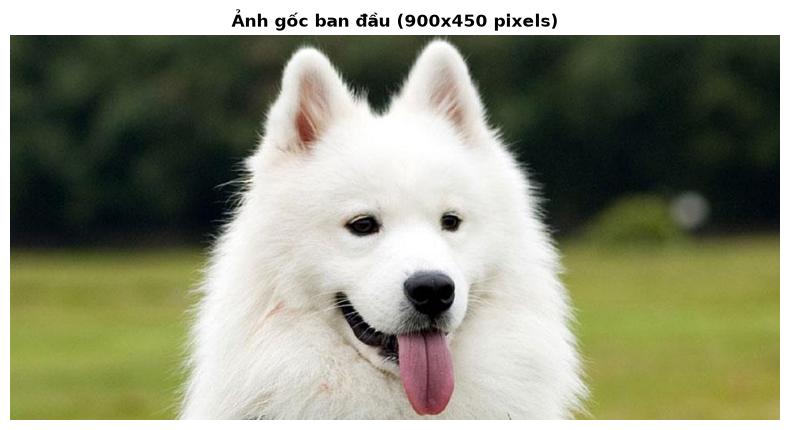

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

image_path = get_data_path("Dataset/dog.png")
image = Image.open(image_path).convert('RGB')
img_array = np.array(image)

rows, cols, channels = img_array.shape

print(f"Đường dẫn file ảnh: {image_path}")
print(f"Kích thước ma trận ảnh: Chiều cao (rows) = {rows}, Chiều rộng (cols) = {cols}, Số kênh màu (channels) = {channels}")
print(f"Tổng số điểm ảnh (pixels): {rows * cols:,}")

plt.figure(figsize=(8, 4.5))
plt.imshow(image)
plt.title(f"Ảnh gốc ban đầu ({cols}x{rows} pixels)", fontsize=12, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

### Câu b: Chuyển ảnh đọc được thành mảng số, chuẩn hóa về đoạn [0, 1] và biến đổi sang mảng 2 chiều
Hướng dẫn: Chia các giá trị pixel cho 255.0 để đưa về đoạn số thực [0, 1], sau đó dùng `reshape(-1, 3)` để chuyển ma trận 3D $(rows, cols, channels)$ thành ma trận 2D $(rows \times cols, 3)$.

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Chuẩn hóa về [0, 1] và chuyển sang mảng 2 chiều (N, 3)
data = img_array.reshape(-1, 3).astype('float32') / 255.0

print(f"Kích thước mảng 2D sau khi làm phẳng: {data.shape}")
print(f"Giá trị nhỏ nhất: {data.min():.2f}, Giá trị lớn nhất: {data.max():.2f}")
print("3 dòng đầu tiên biểu diễn tọa độ màu RGB (đoạn [0, 1]) của 3 pixel đầu tiên:")
print(data[:3])

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước mảng 2D sau khi làm phẳng: (405000, 3)
Giá trị nhỏ nhất: 0.00, Giá trị lớn nhất: 1.00
3 dòng đầu tiên biểu diễn tọa độ màu RGB (đoạn [0, 1]) của 3 pixel đầu tiên:
[[0.25490198 0.30588236 0.19607843]
 [0.23921569 0.2901961  0.18039216]
 [0.22745098 0.2784314  0.1764706 ]]


### Câu c: Chạy thuật toán K-Means với số cụm k = 32 màu
Hướng dẫn: Sử dụng `KMeans(n_clusters=32, random_state=42)` để tìm 32 màu đại diện (tâm cụm), sau đó thay thế mỗi pixel bằng màu của tâm cụm tương ứng.

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

n_colors = 32
kmeans_img = KMeans(n_clusters=n_colors, n_init=10, max_iter=300, random_state=42)
kmeans_img.fit(data)

# Thay thế từng pixel bằng tọa độ màu của tâm cụm gần nhất
compressed_data = kmeans_img.cluster_centers_[kmeans_img.labels_]

print(f"Đã hoàn thành phân cụm K-Means với {n_colors} màu chủ đạo.")
print(f"Kích thước bảng màu tâm cụm: {kmeans_img.cluster_centers_.shape}")
print(f"Kích thước dữ liệu ảnh sau lượng tử hóa màu: {compressed_data.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã hoàn thành phân cụm K-Means với 32 màu chủ đạo.
Kích thước bảng màu tâm cụm: (32, 3)
Kích thước dữ liệu ảnh sau lượng tử hóa màu: (405000, 3)


### Câu d: Khôi phục dạng mảng từ 2 chiều thành 3 chiều như ban đầu và chuyển về thang giá trị [0, 255]
Hướng dẫn: Sử dụng `.reshape(rows, cols, channels)`, nhân lại cho 255 và ép kiểu sang số nguyên không dấu `np.uint8`.

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Nhân lại với 255 và chuyển về kiểu uint8
compressed_img_array = (compressed_data * 255.0).clip(0, 255).astype(np.uint8)
compressed_img_array = compressed_img_array.reshape(rows, cols, channels)

print(f"Kích thước ảnh sau khôi phục: {compressed_img_array.shape}")
print(f"Kiểu dữ liệu: {compressed_img_array.dtype}")
print(f"Khoảng giá trị pixel: [{compressed_img_array.min()}, {compressed_img_array.max()}]")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước ảnh sau khôi phục: (450, 900, 3)
Kiểu dữ liệu: uint8
Khoảng giá trị pixel: [5, 252]


### Câu e: Biểu diễn hình kết quả và so sánh với ảnh gốc ban đầu
Hướng dẫn: Vẽ hai ảnh cạnh nhau bằng `plt.subplot(1, 2, ...)` để đánh giá trực quan chất lượng ảnh sau khi giảm xuống còn 32 màu.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


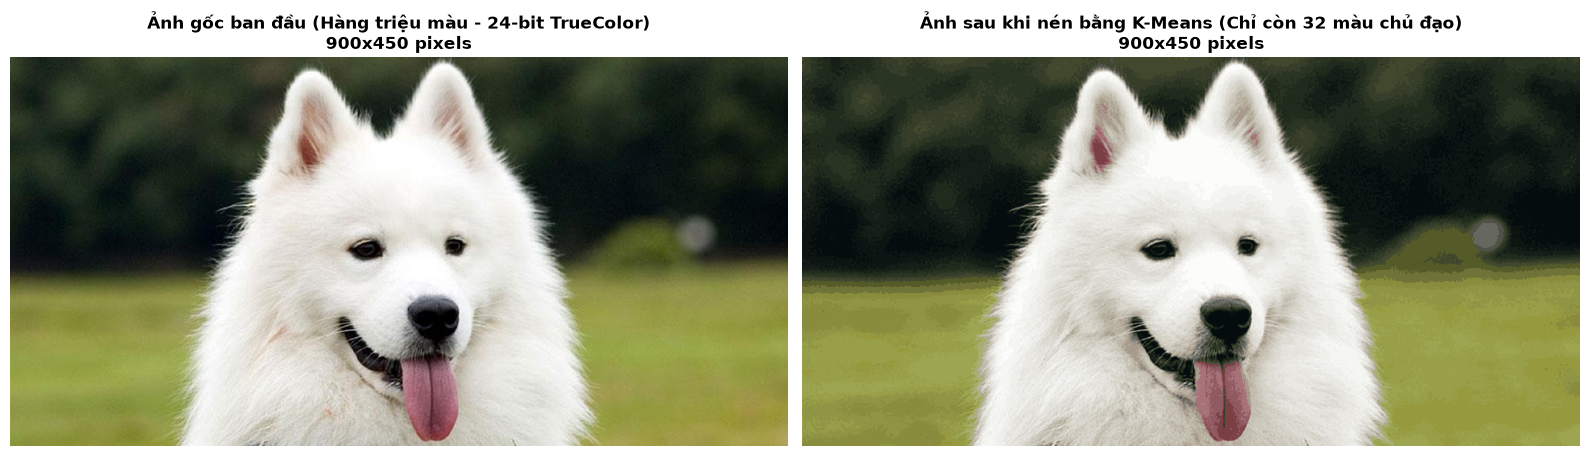

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

plt.figure(figsize=(16, 6))

# Ảnh gốc
plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title(f"Ảnh gốc ban đầu (Hàng triệu màu - 24-bit TrueColor)\n{cols}x{rows} pixels", fontsize=12, fontweight='bold')
plt.axis('off')

# Ảnh sau khi nén 32 màu
plt.subplot(1, 2, 2)
plt.imshow(compressed_img_array)
plt.title(f"Ảnh sau khi nén bằng K-Means (Chỉ còn {n_colors} màu chủ đạo)\n{cols}x{rows} pixels", fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()